In [225]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%precision 3
%matplotlib inline
import warnings
warnings.filterwarnings(action='ignore')

In [226]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings(action='ignore')
import folium
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import time
from googlesearch import search

In [227]:
import re
import matplotlib
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [176]:
df = pd.read_csv('./data/mapo_delivery.csv')

In [177]:
df.head()

,order_id,order_time,pickup_time,delivery_time,store_dong,customer_dong,distance_km,store_type,weather,temp_c,precipitation_mm,wind_mps,rider_id,time_slot,dow,delivery_minutes
0,O000001,2025.10.24 15:46:54,2025-10-24 16:03:49,10/24 04:07 PM,아현동,신수동,1.17,치킨,Sunny,5.1,0.0,1.2,R0062,기타,4,20.9
1,O000002,2025-12-25 06:44:42,2025-12-25 07:00:15,2025-12-25 07:07:36,망원동,도화동,0.20,야식,비,10.9,4.9,4.6,R0362,기타,3,NaN
2,O000003,2025.12.14 12:52:27,2025-12-14 13:07:15,12/14/2025 13:14,용강동,신촌동,0.36,패스트푸드,비,6.3,2.0,5.1,R0223,점심,6,21.9
3,O000004,2025-11-25 02:58,2025-11-25 03:11:05,2025-11-25 03:40:26,공덕동,서교동,3.59,한식,흐림,5.4,0.0,0.8,R0722,심야,1,41.8
4,O000005,2025-11-24 14:18:45,2025-11-24 14:30:10,NaN,성산동,대흥동,2.54,패스트푸드,맑음,8.6,0.0,5.0,R0128,기타,0,44.3


In [178]:
freq, _ = np.histogram(df['delivery_minutes'], bins=30, range=(0, 300))
freq

array([   51,  2706, 12344, 15715,  8893,  2840,   685,   163,    92,
          69,    67,    77,    63,    63,    37,    38,    19,    16,
           6,     5,     5,     3,     2,     2,     1,     1,     1,
           0,     1,     0])

In [179]:
df['delivery_minutes'].value_counts()

delivery_minutes
34.8     193
31.5     189
35.0     188
34.5     188
32.1     188
        ... 
122.2      1
132.6      1
80.4       1
86.3       1
102.5      1
Name: count, Length: 1130, dtype: int64

In [180]:
# 0~10, 10~20, ... 이라는 문자열의 리스트를 작성
freq_class = [f'{i}~{i+30}' for i in range(0, 300, 10)]
# freq_class를 인덱스로 DataFrame을 작성
freq_dist_df = pd.DataFrame({'frequency':freq , 'percent':freq/freq.sum()},
                            index=pd.Index(freq_class,
                                           name='time'))
freq_dist_df

,frequency,percent
time,,
0~30,51,0.001160
10~40,2706,0.061549
20~50,12344,0.280769
30~60,15715,0.357443
40~70,8893,0.202275
50~80,2840,0.064597
60~90,685,0.015581
70~100,163,0.003707
80~110,92,0.002093


In [181]:
freq.sum()

np.int64(43965)

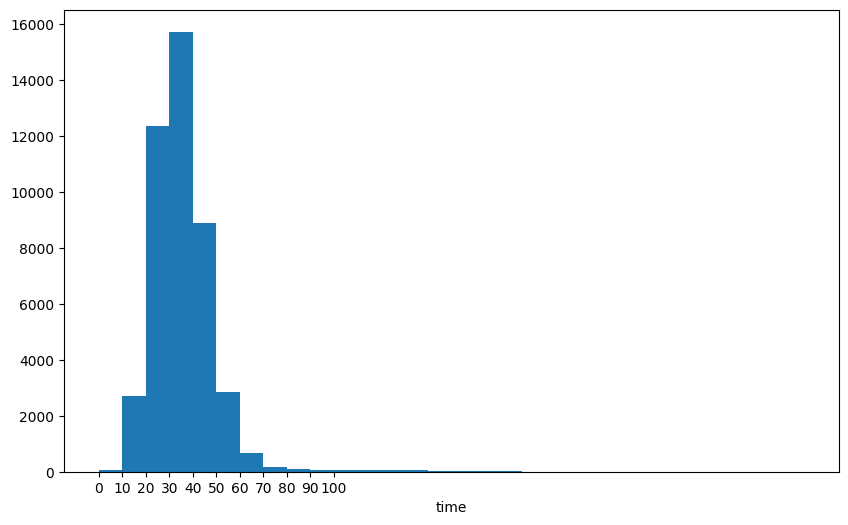

In [182]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df['delivery_minutes'], bins=30, range=(0, 300))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

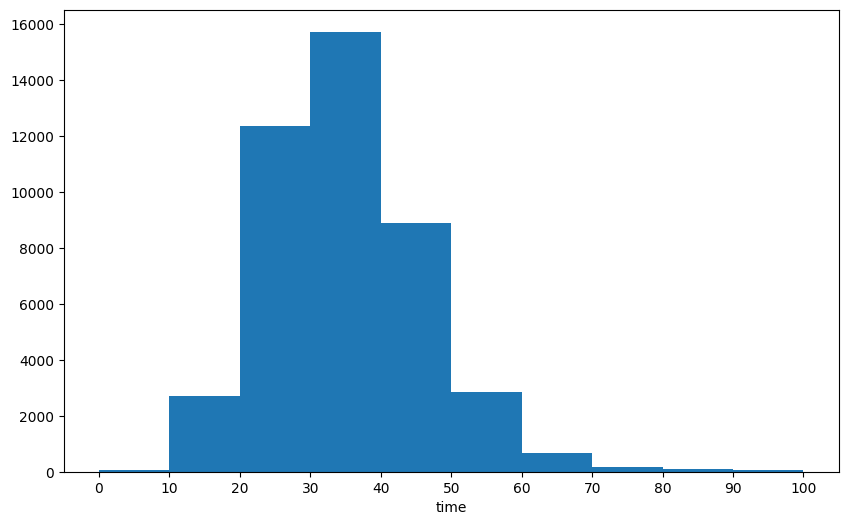

In [183]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

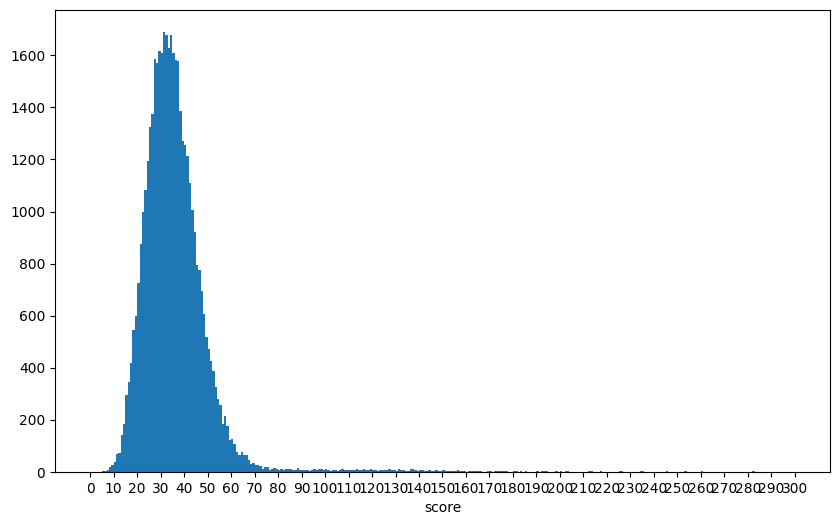

In [184]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))

ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df['delivery_minutes'], bins=300, range=(0, 300))
ax.set_xlabel('score')
ax.set_xticks(np.linspace(0, 300, 30+1))
plt.show()

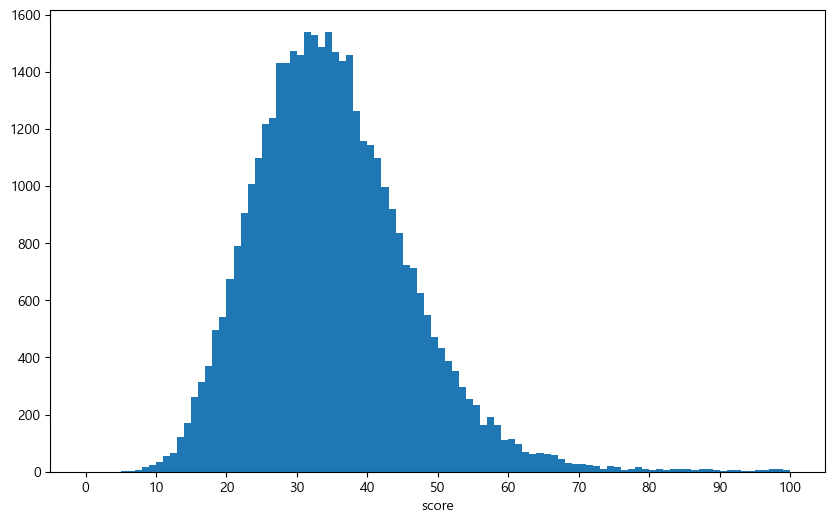

In [242]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))

ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df['delivery_minutes'], bins=100, range=(0, 100))
ax.set_xlabel('score')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

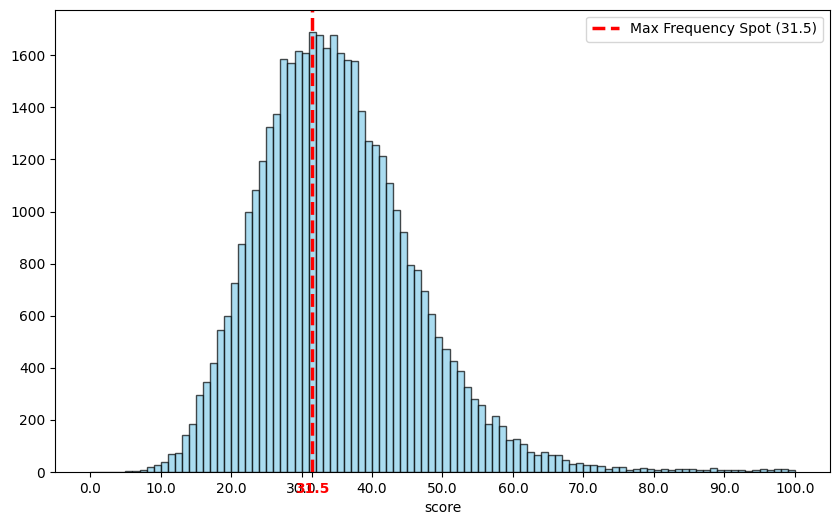

In [186]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)

# 히스토그램 그리기 (동일)
freq, bins_edges, _ = ax.hist(df['delivery_minutes'], bins=100, range=(0, 100), color='skyblue', edgecolor='black', alpha=0.7)

# --- [변경 포인트] 최댓값 위치 찾기 (동일) ---
max_freq = freq.max()
max_idx = freq.argmax()
max_x = (bins_edges[max_idx] + bins_edges[max_idx + 1]) / 2

# --- [추가 포인트 1] 해당 위치에 빨간 점선 긋기 ---
ax.axvline(x=max_x, color='red', linestyle='--', linewidth=2.5, label=f'Max Frequency Spot ({max_x:.1f})')

# 기본 축 설정
ax.set_xlabel('score')

# --- [추가 포인트 2] x축에 해당 좌표 표시하기 ---
# 1. 원래 사용하려던 10개 간격 눈금 정의
standard_ticks = list(np.linspace(0, 100, 10+1))

# 2. 원래 눈금 리스트에 최댓값 좌표(max_x)를 추가하고 정렬
# set()을 사용해 중복을 방지 (만약 max_x가 딱 50.0일 경우 등)
new_ticks = sorted(list(set(standard_ticks + [max_x])))

# 3. 새로운 눈금 위치 설정
ax.set_xticks(new_ticks)

# 4. (선택) 최댓값 라벨만 빨간색으로 변경하기
# 모든 라벨 객체를 가져옴
for label in ax.get_xticklabels():
    # 라벨의 x좌표 위치가 max_x와 같다면 (부동소수점 오차 고려 close 사용)
    if np.isclose(label.get_position()[0], max_x):
        label.set_color('red')       # 글자 색 빨강
        label.set_fontweight('bold') # 굵게

plt.legend() # 빨간 선 라벨 표시
plt.show()

In [187]:
# value_counts가 제일 많은 시간을 반환
df['delivery_minutes'].value_counts().idxmax()

34.800

In [188]:
df = df.dropna()

In [189]:
len(df)

40045

In [190]:
#배달시간 평균
df['delivery_minutes'].mean()

35.949

In [191]:
for i in range(5):
    num = np.random.choice(len(df), size=1, replace=False)
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', df.iloc[num]['delivery_minutes'])

1번째 무작위 추출로 얻은 표본평균 14166    40.6
Name: delivery_minutes, dtype: float64
2번째 무작위 추출로 얻은 표본평균 3661    24.2
Name: delivery_minutes, dtype: float64
3번째 무작위 추출로 얻은 표본평균 2974    32.5
Name: delivery_minutes, dtype: float64
4번째 무작위 추출로 얻은 표본평균 31954    24.7
Name: delivery_minutes, dtype: float64
5번째 무작위 추출로 얻은 표본평균 19243    41.7
Name: delivery_minutes, dtype: float64


In [192]:
#10개만 뽑아서 표본평균 구해본 결과
for i in range(5):
    num = np.random.choice(len(df), size=10, replace=False)
    sample = df.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

1번째 무작위 추출로 얻은 표본평균 37.13
2번째 무작위 추출로 얻은 표본평균 35.14
3번째 무작위 추출로 얻은 표본평균 34.779999999999994
4번째 무작위 추출로 얻은 표본평균 33.62
5번째 무작위 추출로 얻은 표본평균 37.809999999999995


In [193]:
# 5000개 뽑아서 표본평균 구해본 결과
for i in range(5):
    num = np.random.choice(len(df), size=5000, replace=False)
    sample = df.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

1번째 무작위 추출로 얻은 표본평균 36.06728
2번째 무작위 추출로 얻은 표본평균 35.7645
3번째 무작위 추출로 얻은 표본평균 35.63857999999999
4번째 무작위 추출로 얻은 표본평균 36.03094
5번째 무작위 추출로 얻은 표본평균 35.97201999999999


#### 충분히 많은 표본을 뽑으며 실제 결과와 비슷하다고 할 수 있어서 실제  분포를 유추할 수 있다.
#### 우리집에는 항상 50분씩 걸리던대 흠

In [194]:
df.head(0)

,order_id,order_time,pickup_time,delivery_time,store_dong,customer_dong,distance_km,store_type,weather,temp_c,precipitation_mm,wind_mps,rider_id,time_slot,dow,delivery_minutes


In [195]:
df['weather'].value_counts()

weather
맑음          15343
흐림          11693
비            6999
눈            1861
안개           1330
Sunny         177
clear         167
RAIN          153
fog           149
FOG           149
snow          145
Cloudy        145
눈❄            145
SNOW          142
CLEAR         141
overcast      136
안개🌫           134
rain          134
cloudy        132
비☔            132
shower        131
맑 음           130
맑음☀           128
sunny         128
흐림☁           121
Name: count, dtype: int64

In [196]:
import emoji

In [197]:
df['weather'] = df['weather'].astype(str).apply(lambda x: emoji.replace_emoji(x, replace=''))

# 문자열 앞뒤 공백 제거 (이모티콘 지우고 남은 공백 정리)
df['weather'] = df['weather'].str.strip()

In [198]:
df['weather'].value_counts()

weather
맑음          15471
흐림          11814
비            7131
눈            2006
안개           1464
Sunny         177
clear         167
RAIN          153
fog           149
FOG           149
snow          145
Cloudy        145
SNOW          142
CLEAR         141
overcast      136
rain          134
cloudy        132
shower        131
맑 음           130
sunny         128
Name: count, dtype: int64

In [199]:
def clean_weather(text):
  # 문자열 변환 및 공백 제거, 소문자 변환 (영어 대소문자 통일용)
  text = str(text).strip().lower()

  # 키워드 포함 여부에 따라 5개 카테고리로 분류
  if any(k in text for k in ['맑', 'sunny', 'clear']):
    return '맑음'
  elif any(k in text for k in ['흐림', 'cloudy', 'overcast']):
    return '흐림'
  elif any(k in text for k in ['비', 'rain', 'shower']):
    return '비'
  elif any(k in text for k in ['눈', 'snow']):
    return '눈'
  elif any(k in text for k in ['안개', 'fog']):
    return '안개'
  else:
    return '기타'  # 예외 데이터 처리용


# 2. 적용하기
df['clean_weather'] = df['weather'].apply(clean_weather)

# 3. 결과 확인
print(df['clean_weather'].value_counts())

clean_weather
맑음    16214
흐림    12227
비      7549
눈      2293
안개     1762
Name: count, dtype: int64


In [200]:
df_w = df.groupby('clean_weather')

In [201]:
weather_df = pd.crosstab(df['delivery_minutes'], df['clean_weather'])

In [202]:
weather_df

clean_weather,눈,맑음,비,안개,흐림
delivery_minutes,,,,,
5.9,0,0,0,0,1
6.3,0,0,0,0,1
6.6,0,0,0,0,1
7.0,0,1,0,0,1
7.7,0,0,0,0,1
...,...,...,...,...,...
235.7,0,0,1,0,0
245.7,1,0,0,0,0
253.1,0,0,1,0,0


In [203]:
df_sun = df[df['clean_weather'] == '맑음']
df_cloud = df[df['clean_weather'] == '흐림']
df_rain = df[df['clean_weather'] == '비']
df_snow = df[df['clean_weather'] == '눈']
df_fog = df[df['clean_weather'] == '안개']

In [204]:
freq, _ = np.histogram(df_snow['delivery_minutes'], bins=10, range=(0, 100))
freq

array([  2, 117, 493, 725, 563, 230,  93,  24,  11,   3])

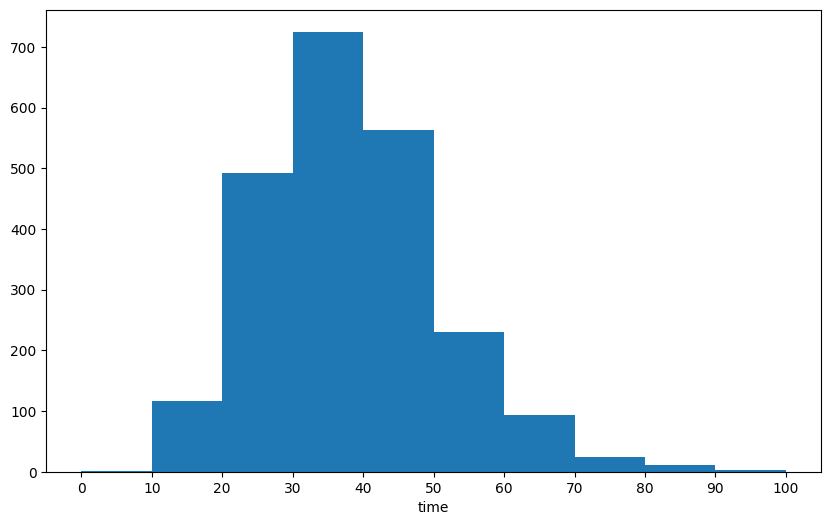

In [205]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_snow['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

In [206]:
print(df_snow['delivery_minutes'].mean())
for i in range(5):
    num = np.random.choice(len(df_snow), size=10, replace=False)
    sample = df_snow.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())
print("size 키웠을때")
for i in range(5):
    num = np.random.choice(len(df_snow), size=1000, replace=False)
    sample = df_snow.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

39.835412123855214
1번째 무작위 추출로 얻은 표본평균 36.13
2번째 무작위 추출로 얻은 표본평균 43.160000000000004
3번째 무작위 추출로 얻은 표본평균 39.37
4번째 무작위 추출로 얻은 표본평균 36.25000000000001
5번째 무작위 추출로 얻은 표본평균 32.55
size 키웠을때
1번째 무작위 추출로 얻은 표본평균 39.7889
2번째 무작위 추출로 얻은 표본평균 40.0256
3번째 무작위 추출로 얻은 표본평균 40.1497
4번째 무작위 추출로 얻은 표본평균 39.45210000000001
5번째 무작위 추출로 얻은 표본평균 39.2849


In [207]:
freq, _ = np.histogram(df_sun['delivery_minutes'], bins=10, range=(0, 100))
freq

array([  22, 1078, 4859, 5959, 3021,  858,  173,   42,   24,   25])

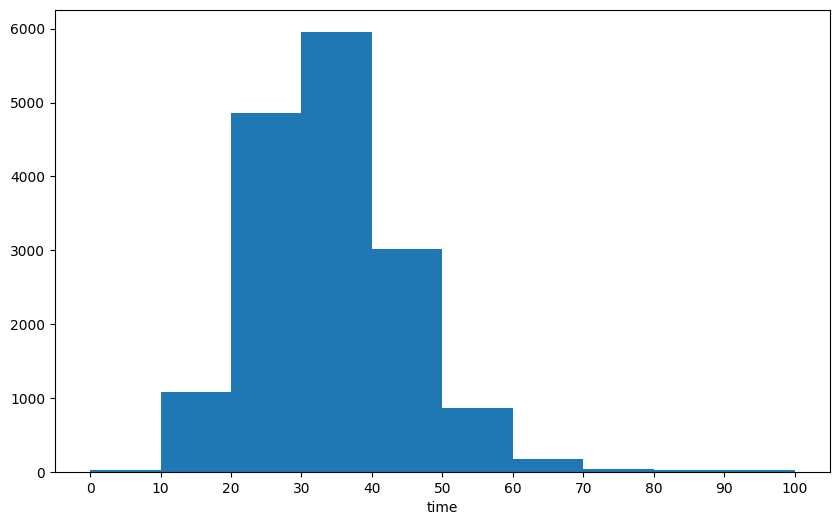

In [208]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_sun['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

In [209]:
print(df_sun['delivery_minutes'].mean())
for i in range(5):
    num = np.random.choice(len(df_sun), size=10, replace=False)
    sample = df_sun.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())
print("size 키웠을때")
for i in range(5):
    num = np.random.choice(len(df_sun), size=1000, replace=False)
    sample = df_sun.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

35.015196743554945
1번째 무작위 추출로 얻은 표본평균 38.06
2번째 무작위 추출로 얻은 표본평균 37.519999999999996
3번째 무작위 추출로 얻은 표본평균 42.33999999999999
4번째 무작위 추출로 얻은 표본평균 35.83
5번째 무작위 추출로 얻은 표본평균 40.10000000000001
size 키웠을때
1번째 무작위 추출로 얻은 표본평균 35.867599999999996
2번째 무작위 추출로 얻은 표본평균 36.175
3번째 무작위 추출로 얻은 표본평균 36.156400000000005
4번째 무작위 추출로 얻은 표본평균 34.621700000000004
5번째 무작위 추출로 얻은 표본평균 35.4344


In [210]:
freq, _ = np.histogram(df_cloud['delivery_minutes'], bins=10, range=(0, 100))
freq

array([  18,  804, 3742, 4489, 2261,  620,  113,   30,   21,   19])

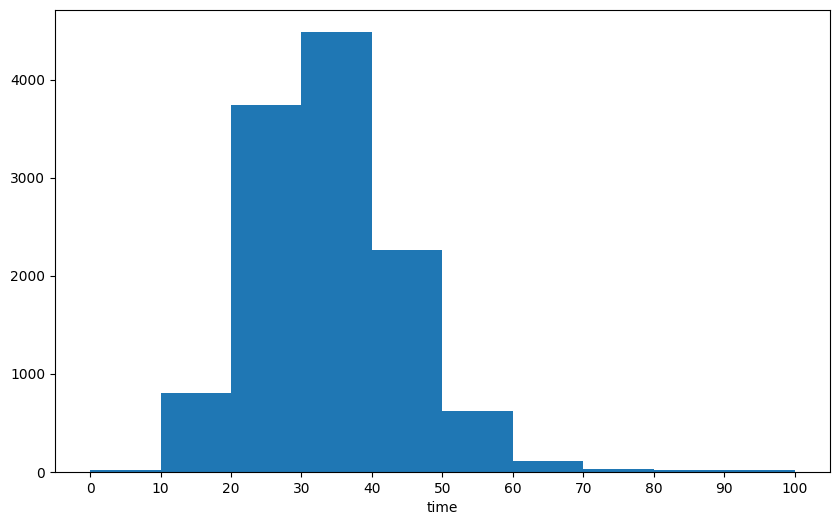

In [211]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_cloud['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

In [212]:
print(df_cloud['delivery_minutes'].mean())
for i in range(5):
    num = np.random.choice(len(df_cloud), size=10, replace=False)
    sample = df_cloud.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())
print("size 키웠을때")
for i in range(5):
    num = np.random.choice(len(df_cloud), size=1000, replace=False)
    sample = df_cloud.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

34.856923202748014
1번째 무작위 추출로 얻은 표본평균 36.300000000000004
2번째 무작위 추출로 얻은 표본평균 32.07
3번째 무작위 추출로 얻은 표본평균 37.00000000000001
4번째 무작위 추출로 얻은 표본평균 38.22
5번째 무작위 추출로 얻은 표본평균 35.769999999999996
size 키웠을때
1번째 무작위 추출로 얻은 표본평균 34.597899999999996
2번째 무작위 추출로 얻은 표본평균 34.7273
3번째 무작위 추출로 얻은 표본평균 34.6604
4번째 무작위 추출로 얻은 표본평균 34.8131
5번째 무작위 추출로 얻은 표본평균 35.019400000000005


In [213]:
freq, _ = np.histogram(df_fog['delivery_minutes'], bins=10, range=(0, 100))
freq

array([  2,  83, 477, 658, 372, 114,  28,   7,   3,   4])

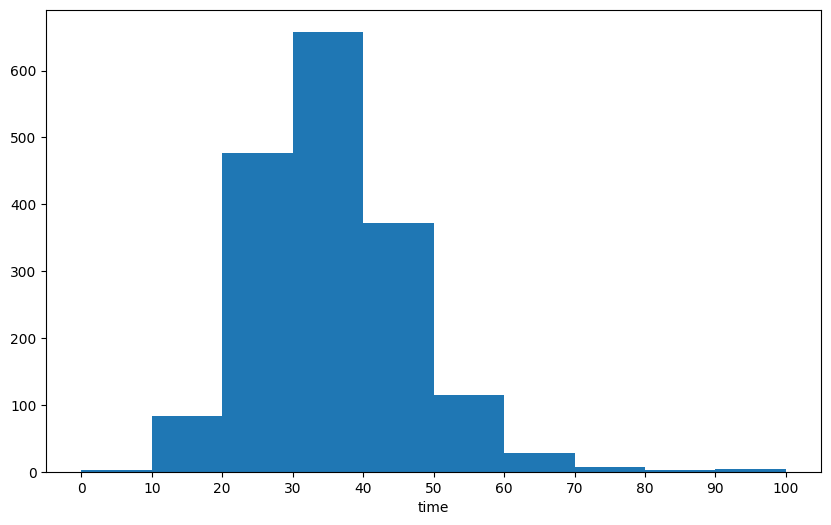

In [214]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_fog['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

In [215]:
print(df_fog['delivery_minutes'].mean())
for i in range(5):
    num = np.random.choice(len(df_fog), size=10, replace=False)
    sample = df_fog.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())
print("size 키웠을때")
for i in range(5):
    num = np.random.choice(len(df_fog), size=1000, replace=False)
    sample = df_fog.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

36.30419977298524
1번째 무작위 추출로 얻은 표본평균 33.6
2번째 무작위 추출로 얻은 표본평균 28.45
3번째 무작위 추출로 얻은 표본평균 41.269999999999996
4번째 무작위 추출로 얻은 표본평균 32.5
5번째 무작위 추출로 얻은 표본평균 37.83
size 키웠을때
1번째 무작위 추출로 얻은 표본평균 35.829699999999995
2번째 무작위 추출로 얻은 표본평균 36.3384
3번째 무작위 추출로 얻은 표본평균 36.8881
4번째 무작위 추출로 얻은 표본평균 36.7734
5번째 무작위 추출로 얻은 표본평균 35.8745


In [216]:
freq, _ = np.histogram(df_rain['delivery_minutes'], bins=10, range=(0, 100))
freq

array([   4,  352, 1692, 2509, 1853,  766,  223,   53,   24,   13])

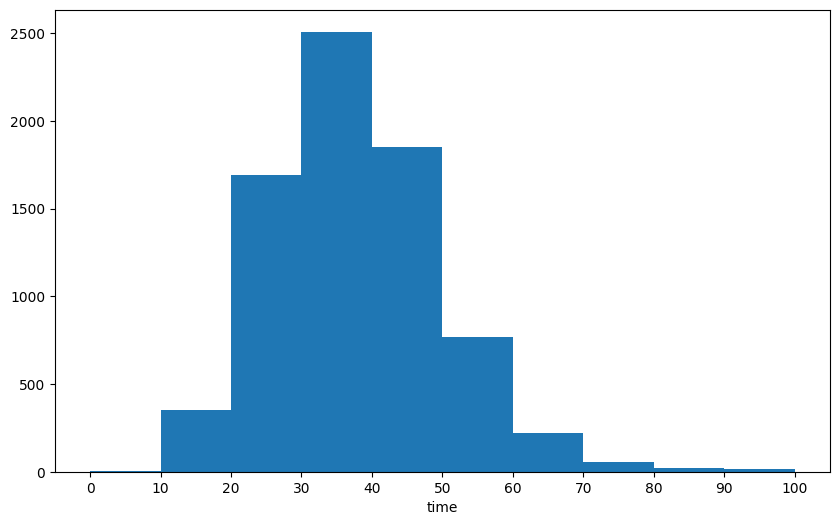

In [217]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_rain['delivery_minutes'], bins=10, range=(0, 100))
ax.set_xlabel('time')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

In [218]:
print(df_rain['delivery_minutes'].mean())
for i in range(5):
    num = np.random.choice(len(df_rain), size=10, replace=False)
    sample = df_rain.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())
print("size 키웠을때")
for i in range(5):
    num = np.random.choice(len(df_rain), size=1000, replace=False)
    sample = df_rain.iloc[num]['delivery_minutes']
    print(f'{i+1}번째 무작위 추출로 얻은 표본평균', sample.mean())

38.459703271956556
1번째 무작위 추출로 얻은 표본평균 48.1
2번째 무작위 추출로 얻은 표본평균 39.83999999999999
3번째 무작위 추출로 얻은 표본평균 40.230000000000004
4번째 무작위 추출로 얻은 표본평균 35.2
5번째 무작위 추출로 얻은 표본평균 37.58
size 키웠을때
1번째 무작위 추출로 얻은 표본평균 39.0783
2번째 무작위 추출로 얻은 표본평균 38.3287
3번째 무작위 추출로 얻은 표본평균 38.184599999999996
4번째 무작위 추출로 얻은 표본평균 38.482800000000005
5번째 무작위 추출로 얻은 표본평균 38.572300000000006


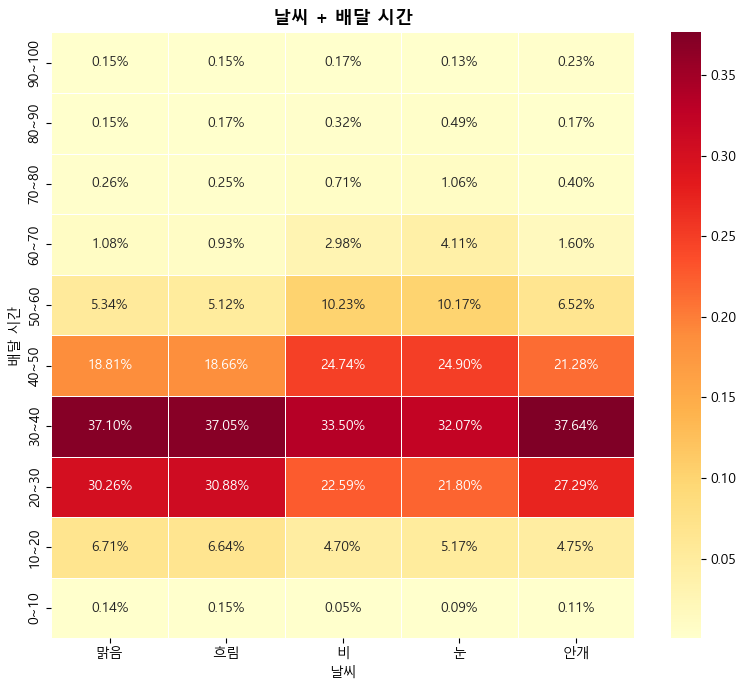

In [232]:
bins = list(range(0, 110, 10))
labels = [f'{i}~{i+10}' for i in range(0, 100, 10)]

df['time_class'] = pd.cut(
    df['delivery_minutes'], bins=bins, labels=labels, right=False
)

heatmap_data = pd.crosstab(
    df['time_class'], df['clean_weather'], normalize='columns'
)

weather_cols = ['맑음', '흐림', '비', '눈', '안개']
heatmap_data = heatmap_data.reindex(
    columns=[c for c in weather_cols if c in heatmap_data.columns]
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2%',
    cmap='YlOrRd',
    linewidths=0.5,
)

plt.title(
    '날씨 + 배달 시간',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('날씨')
plt.ylabel('배달 시간')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [239]:
print(f"눈올때:{len(df_snow)} 눈 위험한데 시키지 말지")
print(f"비올때:{len(df_rain)}")
print(f"안개심할때:{len(df_fog)}")
print(f"맑을때:{len(df_sun)}")
print(f"흐릴때:{len(df_cloud)}")

눈올때:2293 눈 위험한데 시키지 말지
비올때:7549
안개심할때:1762
맑을때:16214
흐릴때:12227


In [234]:
len(df_sun)

16214